In [2]:
import pandas as pd
import numpy as np

In [5]:
df = pd.read_csv("ventas_retail.csv")

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ciudad     500 non-null    str    
 1   categoria  500 non-null    str    
 2   vendedor   500 non-null    str    
 3   trimestre  500 non-null    str    
 4   monto      500 non-null    int64  
 5   unidades   500 non-null    int64  
 6   descuento  500 non-null    float64
dtypes: float64(1), int64(2), str(4)
memory usage: 27.5 KB


In [6]:

totales = {}
for i in range(len(df)):
    ciudad = df["ciudad"].iloc[i]
    monto  = df["monto"].iloc[i]
    if ciudad not in totales:
        totales[ciudad] = 0
    totales[ciudad] += monto

print(totales)


{'Mendoza': np.int64(7706414), 'Tucumán': np.int64(7221605), 'Rosario': np.int64(7938539), 'Córdoba': np.int64(7198111), 'Buenos Aires': np.int64(8855199)}


In [7]:
grupos = df.groupby("ciudad")
print(type(grupos))
# <class 'pandas.core.groupby.DataFrameGroupBy'>


<class 'pandas.api.typing.DataFrameGroupBy'>


In [ ]:
# Total de ventas por ciudad
df.groupby("ciudad")["monto"].sum()


ciudad
Buenos Aires    109
Córdoba          95
Mendoza         112
Rosario          91
Tucumán          93
Name: monto, dtype: int64

In [11]:
# Promedio de ventas por ciudad
df.groupby("ciudad")["monto"].mean()

ciudad
Buenos Aires    81240.357798
Córdoba         75769.589474
Mendoza         68807.267857
Rosario         87236.692308
Tucumán         77651.666667
Name: monto, dtype: float64

In [12]:
# Cantidad de ventas por ciudad
df.groupby("ciudad")["monto"].count()

ciudad
Buenos Aires    109
Córdoba          95
Mendoza         112
Rosario          91
Tucumán          93
Name: monto, dtype: int64

In [13]:
df.groupby(["ciudad", "categoria"])["monto"].sum()


ciudad        categoria  
Buenos Aires  Alimentos      1876997
              Deportes       1372041
              Electrónica    1951331
              Hogar          1607118
              Ropa           2047712
Córdoba       Alimentos      1787767
              Deportes       1778075
              Electrónica    1286509
              Hogar          1292147
              Ropa           1053613
Mendoza       Alimentos       891215
              Deportes       1718730
              Electrónica    1472067
              Hogar          1533021
              Ropa           2091381
Rosario       Alimentos      1715244
              Deportes       1676528
              Electrónica    1526021
              Hogar          1783981
              Ropa           1236765
Tucumán       Alimentos      2595971
              Deportes       1047502
              Electrónica    1445364
              Hogar          1324889
              Ropa            807879
Name: monto, dtype: int64

In [14]:
df.groupby("vendedor")["monto"].agg(["sum", "mean", "count", "max"])


,sum,mean,count,max
vendedor,,,,
Ana Torres,5592010,79885.857143,70,149832
Carlos Vera,5114603,75214.750000,68,145272
Clara Díaz,5051539,77715.984615,65,148273
Lucía Paz,4423650,77607.894737,57,145180
Luis Gómez,5188342,76299.147059,68,149701
María López,4380650,70655.645161,62,146398
Pedro Ruiz,4105135,78944.903846,52,146706
Sofía Herrera,5063939,87309.293103,58,149539


In [16]:
df.groupby("ciudad").agg(
    total_ventas   = ("monto",    "sum"),
    ticket_promedio= ("monto",    "mean"),
    unidades_total = ("unidades", "sum"),
    descuento_max  = ("descuento","max"),
).round(2)


,total_ventas,ticket_promedio,unidades_total,descuento_max
ciudad,,,,
Buenos Aires,8855199,81240.36,1089,0.2
Córdoba,7198111,75769.59,931,0.2
Mendoza,7706414,68807.27,1175,0.2
Rosario,7938539,87236.69,946,0.2
Tucumán,7221605,77651.67,880,0.2


In [ ]:
tabla = df.pivot_table(
    #Valores que se van a mostrar
    values  = "monto",
    #Donde queremos agrupar los datos
    index   = "ciudad",
    #columnas para agrupar los datos
    columns = "categoria",
    #funcion de agregacion
    aggfunc = "sum",
)

print(tabla)

categoria     Alimentos  Deportes  Electrónica    Hogar     Ropa
ciudad                                                          
Buenos Aires    1876997   1372041      1951331  1607118  2047712
Córdoba         1787767   1778075      1286509  1292147  1053613
Mendoza          891215   1718730      1472067  1533021  2091381
Rosario         1715244   1676528      1526021  1783981  1236765
Tucumán         2595971   1047502      1445364  1324889   807879


In [26]:
tabla_multiple = df.pivot_table(
    values  = "monto",
    index   = "ciudad",
    columns = "trimestre",
    aggfunc = ["sum", "mean"],
).round(2)
tabla_multiple = tabla_multiple.rename(columns={"sum": "Total", "mean": "Promedio"}, level=0)
print(tabla_multiple)

                Total                             Promedio            \
trimestre          Q1       Q2       Q3       Q4        Q1        Q2   
ciudad                                                                 
Buenos Aires  2556390  2735824  1607655  1955330  75187.94  88252.39   
Córdoba       1632413  1596225  1932245  2037228  77733.95  69401.09   
Mendoza       2500488  1617051  1907793  1681082  73543.76  64682.04   
Rosario       1957784  2212611  2461971  1306173  81574.33  96200.48   
Tucumán       1536296  2079097  1103564  2502648  73156.95  77003.59   

                                  
trimestre           Q3        Q4  
ciudad                            
Buenos Aires  76555.00  85014.35  
Córdoba       80510.21  75452.89  
Mendoza       70659.00  64657.00  
Rosario       82065.70  93298.07  
Tucumán       91963.67  75837.82  


In [21]:
# groupby con dos columnas → MultiIndex
por_ciudad_trim = df.groupby(["ciudad", "trimestre"])["monto"].sum()
print(por_ciudad_trim)


ciudad        trimestre
Buenos Aires  Q1           2556390
              Q2           2735824
              Q3           1607655
              Q4           1955330
Córdoba       Q1           1632413
              Q2           1596225
              Q3           1932245
              Q4           2037228
Mendoza       Q1           2500488
              Q2           1617051
              Q3           1907793
              Q4           1681082
Rosario       Q1           1957784
              Q2           2212611
              Q3           2461971
              Q4           1306173
Tucumán       Q1           1536296
              Q2           2079097
              Q3           1103564
              Q4           2502648
Name: monto, dtype: int64


In [32]:
# unstack() convierte el trimestre (nivel interno) en columnas
tabla_unstacked = por_ciudad_trim.unstack(level=1)
print(tabla_unstacked)


trimestre          Q1       Q2       Q3       Q4
ciudad                                          
Buenos Aires  2556390  2735824  1607655  1955330
Córdoba       1632413  1596225  1932245  2037228
Mendoza       2500488  1617051  1907793  1681082
Rosario       1957784  2212611  2461971  1306173
Tucumán       1536296  2079097  1103564  2502648


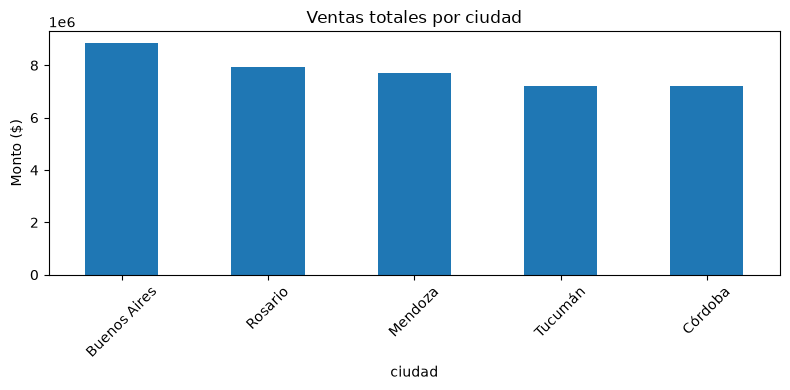

In [37]:
import matplotlib.pyplot as plt

# Ventas totales por ciudad — gráfico de barras
totales_ciudad = df.groupby("ciudad")["monto"].sum().sort_values(ascending=False)

totales_ciudad.plot(kind="bar", figsize=(8, 4), title="Ventas totales por ciudad")
plt.ylabel("Monto ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


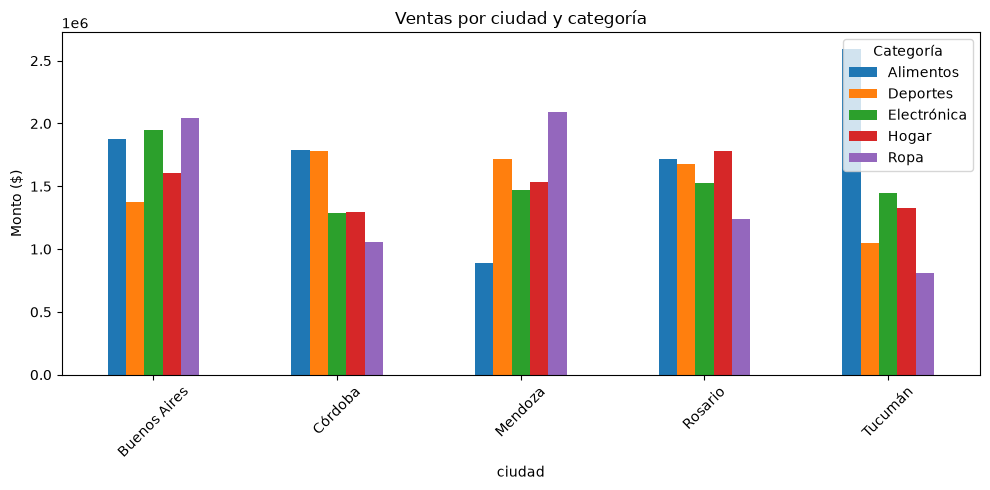

In [35]:
tabla.plot(kind="bar", figsize=(10, 5), title="Ventas por ciudad y categoría")
plt.ylabel("Monto ($)")
plt.xticks(rotation=45)
plt.legend(title="Categoría")
plt.tight_layout()
plt.show()


=== Ciudad con más ventas ===
ciudad
Buenos Aires    8855199
Rosario         7938539
Mendoza         7706414
Tucumán         7221605
Córdoba         7198111
Name: monto, dtype: int64

Ganadora: Buenos Aires ($8,855,199)

=== Ingresos por categoría y trimestre ===
trimestre         Q1       Q2       Q3       Q4
categoria                                      
Alimentos    2018617  2420102  1798483  2629992
Deportes     2331622  1667151  2095008  1499095
Electrónica  2180347  2155875  1656060  1689010
Hogar        1420609  2045656  1688955  2385936
Ropa         2232176  1952024  1774722  1278428

=== Ticket promedio por vendedor ===
vendedor
Sofía Herrera    87309.0
Ana Torres       79886.0
Pedro Ruiz       78945.0
Clara Díaz       77716.0
Lucía Paz        77608.0
Luis Gómez       76299.0
Carlos Vera      75215.0
María López      70656.0
Name: monto, dtype: float64

Mejor ticket promedio: Sofía Herrera ($87,309)


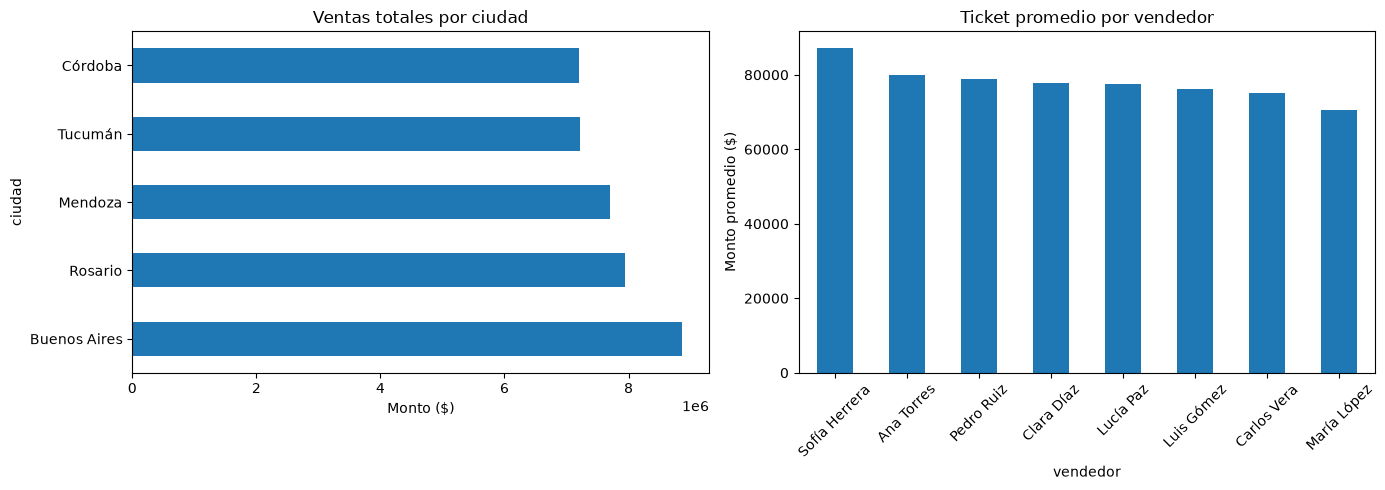

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("ventas_retail.csv")

# ¿Qué ciudad vende más?
print("=== Ciudad con más ventas ===")
por_ciudad = df.groupby("ciudad")["monto"].sum().sort_values(ascending=False)
print(por_ciudad)
print(f"\nGanadora: {por_ciudad.index[0]} (${por_ciudad.iloc[0]:,.0f})")

# ¿Qué categoría genera más ingresos por trimestre?
print("\n=== Ingresos por categoría y trimestre ===")
tabla_trim = df.pivot_table(
    values    = "monto",
    index     = "categoria",
    columns   = "trimestre",
    aggfunc   = "sum",
    fill_value= 0,
)
print(tabla_trim)

# ¿Qué vendedor tiene el ticket promedio más alto?
print("\n=== Ticket promedio por vendedor ===")
ticket = df.groupby("vendedor")["monto"].mean().sort_values(ascending=False)
print(ticket.round(0))
print(f"\nMejor ticket promedio: {ticket.index[0]} (${ticket.iloc[0]:,.0f})")

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

por_ciudad.plot(kind="barh", ax=axes[0], title="Ventas totales por ciudad")
axes[0].set_xlabel("Monto ($)")

ticket.plot(kind="bar", ax=axes[1], title="Ticket promedio por vendedor")
axes[1].set_ylabel("Monto promedio ($)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()
